# 5.5.2 · Territórios Quilombolas: tabela completa e mapas de detalhe

**Objetivo:** responder às solicitações do orientador usando a base espacial da **versão 2**, sem eliminar registros.

O notebook produz:
1. Tabela de **todas as unidades territoriais quilombolas com ocorrência**, com nome, etapa, UF informada no território, registros, glebas e referências BACEN distintas, áreas acumulada e da união. A planilha completa inclui a soma dos valores das linhas, identificada como tal.
2. Mapa geral do Cerrado, com **contornos azuis fortes dos territórios**, glebas em laranja e interseções em vermelho.
3. Mapa da **UF com mais registros de interseção**, com limite estadual, limites dos territórios com ocorrência e glebas vinculadas aos registros dessa UF.
4. Dois mapas individuais dos **territórios com mais registros**, selecionados no conjunto completo.
5. CSVs, Excel, tabelas HTML copiáveis para o Word, figuras PNG a 400 dpi/PDF/SVG, legendas e relatório de conferência, reunidos em ZIP.

**Unidade de seleção:** “caso” significa uma linha original do arquivo espacial, e não concessão irregular, produtor ou gleba única. Empates são resolvidos por nome e ID, sem usar a área como critério oculto. A UF é determinada pela interseção geométrica com seus limites; um registro pode alcançar mais de uma UF. Cada linha é contada uma vez por UF, independentemente do número de partes.

**Limites dos territórios:** são recuperados de `GEOMETRIA_QUILOMBOLA_WKT` da própria base V2, preservando a versão utilizada no cruzamento. São mostrados os territórios **com ocorrência na amostra**, não um inventário de todos os territórios existentes no país. Os polígonos das glebas vêm de `GT_GEOMETRIA`; não são substituídos pelos polígonos de interseção nem por pontos.

Os valores anteriores (368 registros, 300 glebas e 43 unidades) são referências para conferência, nunca resultados fixados no código. Os mapas de contexto não refazem a seleção original das glebas pelo Cerrado.


**Correção da identificação:** o nome vem de `QUIL_NM_COMUNID`. O rótulo `_UNIDADE_NOME` do relatório anterior não reconheceu essa coluna e marcou as unidades como sem nome. A associação é feita pelo ID original, sem inferência por proximidade ou pelo nome do município. A auditoria exporta ambas as identificações.


## 1. Preparar o Colab

In [1]:
%pip -q install "pandas>=2.2,<3" "numpy>=1.26,<3" "geopandas>=1.0,<2" "shapely>=2.0,<3" "matplotlib>=3.8,<4" "pyproj>=3.6,<4" "pyogrio>=0.9,<1" "openpyxl>=3.1,<4" "requests>=2.31,<3" "google-api-python-client>=2,<3"
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 2. Caminhos e parâmetros já preenchidos
A entrada é a base espacial exportada na versão 2, **não a base de partes municipais**, que multiplicaria as linhas. Se o caminho não existir, o notebook baixa o arquivo pelo ID confirmado, mediante autenticação no seu Drive.

Os arquivos vetoriais do IBGE servem de contexto cartográfico: biomas 2019 e UFs 2024. Para usar outra edição, informe os arquivos e as fontes abaixo; isso ficará registrado nos metadados. O CRS de cálculo é **EPSG:5880**, que reproduz as áreas do relatório V2. Os WKT de entrada estão em **SIRGAS 2000 / EPSG:4674**. Não são aplicados cortes por tamanho mínimo de área nem simplificação nos cálculos.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
RAIZ = Path('/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios')
PASTA_V2 = RAIZ / 'intersecoes' / 'quilombolas' / 'resultados_por_id_gleba2' / 'versao_2'
ARQUIVO_BASE = PASTA_V2 / 'bases_analiticas' / 'base_registros_espaciais_sem_deduplicacao.csv'
ID_DRIVE_BASE = '1xkegDTlWPioux9pf2svVfkEHzVI4uNhT'
ARQUIVO_UFS = None       # opcional: caminho de ZIP, SHP, GPKG ou GeoJSON
ARQUIVO_BIOMAS = None    # opcional: caminho de ZIP, SHP, GPKG ou GeoJSON
FONTE_UFS = 'IBGE, Malha de Unidades da Federação, 2024'
FONTE_BIOMAS = 'IBGE, Biomas do Brasil, 2019, escala 1:250.000'
URL_UFS = 'https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2024/Brasil/BR_UF_2024.zip'
URL_BIOMAS = 'https://geoftp.ibge.gov.br/informacoes_ambientais/estudos_ambientais/biomas/vetores/Biomas_250mil.zip'
COLUNA_UF = 'SIGLA_UF'
COLUNA_BIOMA = 'Bioma'
CRS_WKT = 'EPSG:4674'
CRS_ANALISE = 'EPSG:5880'
ANOS = [2021, 2022, 2023, 2024, 2025]
NUMERO_TERRITORIOS_DETALHE = 2
DPI = 400
FORMATOS = ['png', 'pdf', 'svg']
MOSTRAR_FIGURAS = True
BAIXAR_ZIP = True
TOLERANCIA_AREA_HA = 0.05
REFERENCIA = dict(registros=368,glebas=300,territorios=43,refs=234,area_acumulada_ha=15016.01,
                  area_uniao_ha=9367.44,soma_valores_linhas=184451603.64)
EXECUCAO = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
SAIDA = RAIZ / 'complementos_quilombolas_5_5_2' / EXECUCAO
CACHE = RAIZ / 'complementos_quilombolas_5_5_2' / '_cache'
for p in [SAIDA,CACHE,SAIDA/'tabelas',SAIDA/'mapas']:p.mkdir(parents=True,exist_ok=True)
print('Base:',ARQUIVO_BASE)
print('Resultados:',SAIDA)


Base: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/quilombolas/resultados_por_id_gleba2/versao_2/bases_analiticas/base_registros_espaciais_sem_deduplicacao.csv
Resultados: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_quilombolas_5_5_2/20260918_003856_312065


## 3. Localizar a base e os limites cartográficos

In [3]:
import json, hashlib, zipfile, re, math, platform, textwrap
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box
from pyproj import CRS, Transformer, Geod
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from IPython.display import display
ORIGENS={}

def hash_arquivo(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()

def entrada_drive():
    if ARQUIVO_BASE.is_file():return ARQUIVO_BASE
    from google.colab import auth
    import google.auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    auth.authenticate_user();cred,_=google.auth.default()
    srv=build('drive','v3',credentials=cred,cache_discovery=False)
    meta=srv.files().get(fileId=ID_DRIVE_BASE,fields='id,name,size,modifiedTime,md5Checksum',supportsAllDrives=True).execute()
    if meta['name']!=ARQUIVO_BASE.name:raise ValueError('Confira o ID: o nome da base mudou: '+meta['name'])
    dest=CACHE/meta['name'];marcador=dest.with_suffix('.origem.json')
    pronto=dest.exists() and marcador.exists() and json.loads(marcador.read_text())==meta and dest.stat().st_size==int(meta['size'])
    if not pronto:
        tmp=dest.with_suffix('.part')
        with tmp.open('wb') as f:
            dl=MediaIoBaseDownload(f,srv.files().get_media(fileId=ID_DRIVE_BASE,supportsAllDrives=True),chunksize=16*1024*1024)
            fim=False
            while not fim:
                status,fim=dl.next_chunk(num_retries=3)
                if status:print(f'Download da base: {100*status.progress():.0f}%')
        if tmp.stat().st_size!=int(meta['size']):raise RuntimeError('Download incompleto.')
        tmp.replace(dest);marcador.write_text(json.dumps(meta),encoding='utf-8')
    ORIGENS['drive']=meta
    return dest

def obter_vetor(local,url,nome):
    if local:
        p=Path(local)
        if not p.is_file():raise FileNotFoundError(p)
        return p
    p=CACHE/nome
    if not (p.is_file() and zipfile.is_zipfile(p)):
        tmp=p.with_suffix('.part')
        with requests.get(url,stream=True,timeout=(30,180)) as r:
            r.raise_for_status()
            with tmp.open('wb') as f:
                for b in r.iter_content(1024*1024):f.write(b)
        if not zipfile.is_zipfile(tmp):raise ValueError('O download não retornou ZIP: '+url)
        tmp.replace(p)
    return p

def ler_vetor(p):
    z=gpd.read_file('zip://'+str(p) if str(p).lower().endswith('.zip') else p)
    if z.crs is None:raise ValueError('Vetor sem referência espacial: '+str(p))
    return z

CAMINHO=entrada_drive()
pufs=obter_vetor(ARQUIVO_UFS,URL_UFS,'BR_UF_2024.zip')
pbiomas=obter_vetor(ARQUIVO_BIOMAS,URL_BIOMAS,'Biomas_250mil_2019.zip')
for nome,p in [('base',CAMINHO),('ufs',pufs),('biomas',pbiomas)]:
    ORIGENS[nome]={'arquivo':str(p),'bytes':p.stat().st_size,'sha256':hash_arquivo(p)}
ufs=ler_vetor(pufs);biomas=ler_vetor(pbiomas)
if COLUNA_UF not in ufs or COLUNA_BIOMA not in biomas:raise ValueError('Confira as colunas dos arquivos de contexto.')
ufs=ufs[[COLUNA_UF,'geometry']].rename(columns={COLUNA_UF:'UF'}).to_crs(CRS_ANALISE)
ufs['UF']=ufs.UF.astype(str).str.strip()
if ufs.UF.duplicated().any():ufs=ufs.dissolve(by='UF',as_index=False)
cer=biomas.loc[biomas[COLUNA_BIOMA].astype(str).str.strip().str.casefold().eq('cerrado'),['geometry']].to_crs(CRS_ANALISE)
if cer.empty:raise ValueError('Cerrado não encontrado no vetor de biomas.')
# Reparos apenas nos limites de contexto; qualquer alteração fica registrada.
ORIGENS['reparos_contexto']={}
for nome,z in [('ufs',ufs),('cerrado',cer)]:
    if z.geometry.isna().any() or z.geometry.is_empty.any():raise ValueError('Geometria ausente no contexto '+nome)
    mask=~z.is_valid;ORIGENS['reparos_contexto'][nome]=int(mask.sum())
    if mask.any():z.loc[mask,'geometry']=z.loc[mask,'geometry'].make_valid()
    if not z.geom_type.isin(['Polygon','MultiPolygon']).all():raise ValueError('Contexto não poligonal: '+nome)
cerrado=cer.geometry.union_all()
print('Entradas localizadas; SHA-256 registrado para reprodutibilidade.')


Entradas localizadas; SHA-256 registrado para reprodutibilidade.


## 4. Ler e validar as geometrias e os identificadores
Nenhum registro é eliminado por repetição. As cópias distintas de território e gleba são construídas **somente para desenhar os mapas**. Os totais continuam usando todas as linhas.

O notebook interrompe a execução se houver chaves essenciais ausentes, ano fora do período, WKT ausente/inválido/não poligonal ou associação ambígua do identificador. Não corrige silenciosamente a base V2. Cada território é identificado por `QUIL_ID_INTERNO`, preservando unidades com mesmo nome e etapas ou códigos diferentes. Esses IDs internos não são tratados como códigos oficiais permanentes do Incra.


In [4]:
d=pd.read_csv(CAMINHO,sep=';',encoding='utf-8-sig',dtype=str,keep_default_na=False,on_bad_lines='error')
C={'linha':'_ID_LINHA_ORIGINAL','gleba':'ID_GLEBA2','ref':'REF_BACEN','ano':'ANO_OPERACAO',
   'unidade':'QUIL_ID_INTERNO','codigo_territorio':'QUIL_CD_QUILOMB','nome':'QUIL_NM_COMUNID','fase':'QUIL_FASE','uf_territorio':'QUIL_CD_UF',
   'valor':'VL_PARC_CREDITO','area_csv':'AREA_INTERSECAO_HA','inter':'GEOMETRIA_INTERSECAO_WKT',
   'geom_gleba':'GT_GEOMETRIA','geom_territorio':'GEOMETRIA_QUILOMBOLA_WKT'}
faltam=set(C.values())-set(d.columns)
if faltam:raise ValueError('Colunas necessárias ausentes: '+str(sorted(faltam)))
for k in ['linha','gleba','ref','ano','unidade']:
    d[C[k]]=d[C[k]].astype(str).str.strip()
    if d[C[k]].str.lower().isin(['','nan','none','null','<na>']).any():raise ValueError('Chave essencial ausente: '+C[k])
# Nome e etapa são atributos; ausência não exclui registros.
for k in ['codigo_territorio','nome','fase','uf_territorio']:
    d[C[k]]=d[C[k]].astype(str).str.strip()
    vazio=d[C[k]].str.lower().isin(['','nan','none','null','<na>'])
    if k=='nome':d.loc[vazio,C[k]]='Sem denominação — ID '+d.loc[vazio,C['unidade']]
    else:d.loc[vazio,C[k]]='Não informado'
if d[C['linha']].duplicated().any():raise ValueError('ID de linha repetido: verifique se foi usada a base de partes municipais.')
ano=pd.to_numeric(d[C['ano']],errors='raise')
if not ano.isin(ANOS).all():raise ValueError('Ano fora de 2021–2025; nenhuma linha foi removida automaticamente.')
if 'QUIL_EPSG' in d and not d.QUIL_EPSG.eq('4674').all():raise ValueError('QUIL_EPSG difere do CRS_WKT esperado; confira a origem.')

def numero_pt(v):
    s=str(v).strip()
    if s.lower() in ['', 'nan', 'none', 'null']:return np.nan
    if ',' in s:s=s.replace('.','').replace(',','.')
    try:return float(s)
    except ValueError:raise ValueError('Número não interpretável: '+s)

def geometrias(coluna):
    z=gpd.GeoSeries.from_wkt(d[coluna],crs=CRS_WKT,on_invalid='raise').force_2d()
    problemas=z.isna()|z.is_empty|~z.is_valid|~z.geom_type.isin(['Polygon','MultiPolygon'])
    if problemas.any():
        d.loc[problemas,[C['linha'],C['unidade'],C['gleba']]].to_csv(SAIDA/f'problemas_{coluna}.csv',index=False,sep=';')
        raise ValueError('Há geometrias ausentes, inválidas ou não poligonais em '+coluna+'. Confira o CSV de diagnóstico.')
    if not z.bounds.apply(lambda s:np.isfinite(s).all()).all():raise ValueError('Coordenadas não finitas.')
    b=z.total_bounds
    if not(-80<b[0]<-30 and -40<b[1]<10 and -80<b[2]<-30 and -40<b[3]<10):raise ValueError('Coordenadas incompatíveis com WKT geográfico do Brasil.')
    return z.to_crs(CRS_ANALISE)

inter=geometrias(C['inter']);gg=geometrias(C['geom_gleba']);gt=geometrias(C['geom_territorio'])
x=pd.DataFrame({k:d[v] for k,v in C.items() if k not in ['inter','geom_gleba','geom_territorio','valor','area_csv']})
x['valor']=d[C['valor']].map(numero_pt)
x['area_csv']=d[C['area_csv']].map(numero_pt)
if x.area_csv.isna().any():raise ValueError('Área de origem ausente.')
x['area_ha']=inter.area/10000
if x.area_ha.le(0).any():raise ValueError('Interseção com área não positiva.')
x=gpd.GeoDataFrame(x,geometry=inter,crs=CRS_ANALISE)

# Um identificador deve ter uma única representação; igualdade topológica aqui
# é apenas uma verificação de integridade das cópias para desenho.
def copia_unica(chave,geoms,atributos):
    result=[]
    for ident,idx in x.groupby(chave,sort=False).groups.items():
        ids=list(idx);a=geoms.iloc[ids[0]]
        if not all(a.equals(geoms.iloc[i]) for i in ids):raise ValueError('Geometrias divergentes para '+chave+'='+str(ident))
        for c in atributos:
            if x.loc[ids,c].nunique()!=1:raise ValueError('Atributo divergente '+c+' em '+str(ident))
        result.append({chave:ident,**{c:x.loc[ids[0],c] for c in atributos},'geometry':a})
    return gpd.GeoDataFrame(result,geometry='geometry',crs=CRS_ANALISE)

territorios=copia_unica('unidade',gt,['codigo_territorio','nome','fase','uf_territorio'])
glebas=copia_unica('gleba',gg,[])
def csv(t,n):t.to_csv(SAIDA/'tabelas'/n,index=False,sep=';',decimal=',',encoding='utf-8-sig',float_format='%.9f')
area_check=x[['linha','unidade','gleba','area_csv','area_ha']].copy();area_check['diferenca_ha']=area_check.area_ha-area_check.area_csv
csv(area_check,'conferencia_areas_por_linha.csv')
if area_check.diferenca_ha.abs().max()>TOLERANCIA_AREA_HA:
    raise ValueError('As áreas calculadas divergem das áreas da V2. Confira CRS e conferencia_areas_por_linha.csv.')
print(f'{len(x)} registros preservados; {len(glebas)} glebas distintas; {len(territorios)} unidades territoriais.')

# Rastreabilidade da recuperação dos nomes, preservando a identificação anterior.
auditoria_nomes=d[[C['unidade'],C['nome'],C['fase'],C['uf_territorio']]].copy()
auditoria_nomes['rotulo_relatorio_anterior']=d['_UNIDADE_NOME'] if '_UNIDADE_NOME' in d else 'Não disponível'
auditoria_nomes['municipios_atributo']=d['QUIL_NM_MUNICIP'] if 'QUIL_NM_MUNICIP' in d else ''
auditoria_nomes=auditoria_nomes.drop_duplicates().sort_values(C['unidade'])
csv(auditoria_nomes,'auditoria_identificacao_territorios.csv')
print('Identificação do código 17:')
display(auditoria_nomes.loc[auditoria_nomes[C['unidade']].eq('17')])


368 registros preservados; 300 glebas distintas; 43 unidades territoriais.
Identificação do código 17:


,QUIL_ID_INTERNO,QUIL_NM_COMUNID,QUIL_FASE,QUIL_CD_UF,rotulo_relatorio_anterior,municipios_atributo
0,17,BARRA DO AROEIRA,RTID,TO,Território quilombola sem nome - ID 17,SANTA TEREZA DONOVO ACORDO LAGOA DO TOCANTINS


## 5. Totais por Território Quilombola e conferência global
Áreas calculadas em EPSG:5880, em hectares, reproduzindo a V2. A área acumulada soma todas as linhas. A área da união é calculada sobre a união geométrica, **não pela soma das áreas de grupos**. O total global de glebas e referências também é recalculado e não somado entre territórios.

A soma monetária é a **soma dos valores presentes nas linhas**, que pode repetir valores de uma operação/ordem. Não representa crédito exclusivo destinado à área sobreposta nem valor irregular. Campos monetários ausentes são contados; não são transformados silenciosamente em zero.


In [5]:
def metricas(z):
    return dict(registros=len(z),glebas=z.gleba.nunique(),refs=z.ref.nunique(),
        area_acumulada_ha=float(z.area_ha.sum()),area_uniao_ha=float(z.geometry.union_all().area/10000),
        soma_valores_linhas=float(z.valor.sum(min_count=1)),linhas_sem_valor=int(z.valor.isna().sum()))
res=[]
for unidade,z in x.groupby('unidade',sort=False):
    t=territorios.loc[territorios.unidade.eq(unidade)].iloc[0]
    res.append({'unidade':unidade,'codigo_territorio':t.codigo_territorio,'nome':t['nome'],'fase':t.fase,'uf_territorio':t.uf_territorio,**metricas(z)})
por_territorio=pd.DataFrame(res).sort_values(['registros','nome','unidade'],ascending=[False,True,True]).reset_index(drop=True)
por_territorio.insert(0,'posicao',np.arange(1,len(por_territorio)+1))
geral={**metricas(x),'territorios':len(territorios)}
controle=[]
for k,anterior in REFERENCIA.items():
    valor=geral[k];tol=TOLERANCIA_AREA_HA if k.startswith('area') else (0.02 if k=='soma_valores_linhas' else 0)
    controle.append({'indicador':k,'calculado':valor,'referencia_v2':anterior,'diferenca':valor-anterior,'confere':abs(valor-anterior)<=tol})
conferencia=pd.DataFrame(controle)
csv(conferencia,'conferencia_com_texto_5_5_2.csv')
if not conferencia.confere.all():
    print('ATENÇÃO: há divergências com a versão anterior; os produtos usarão os resultados calculados, sem forçar os totais.')
assert por_territorio.registros.sum()==len(x)
assert np.isclose(por_territorio.area_acumulada_ha.sum(),geral['area_acumulada_ha'])
csv(por_territorio,'totais_por_territorio_quilombola_completo.csv')
csv(pd.DataFrame([geral]),'totais_gerais.csv')
TOP_TERRITORIOS=por_territorio.head(NUMERO_TERRITORIOS_DETALHE).unidade.tolist()
display(conferencia);display(por_territorio)
print('territórios para mapas individuais:',por_territorio.head(NUMERO_TERRITORIOS_DETALHE)[['nome','fase','registros']].to_dict('records'))

por_etapa=pd.DataFrame([{'etapa':fase,'territorios':z.unidade.nunique(),**metricas(z)} for fase,z in x.groupby('fase')]).sort_values('registros',ascending=False)
csv(por_etapa,'totais_por_etapa_regularizacao.csv')
# Não somar glebas, referências nem união entre grupos.


,indicador,calculado,referencia_v2,diferenca,confere
0,registros,3.680000e+02,3.680000e+02,0.000000e+00,True
1,glebas,3.000000e+02,3.000000e+02,0.000000e+00,True
2,territorios,4.300000e+01,4.300000e+01,0.000000e+00,True
3,refs,2.340000e+02,2.340000e+02,0.000000e+00,True
4,area_acumulada_ha,1.501601e+04,1.501601e+04,-4.247001e-03,True
5,area_uniao_ha,9.367437e+03,9.367440e+03,-2.732053e-03,True
6,soma_valores_linhas,1.844516e+08,1.844516e+08,2.980232e-08,True


,posicao,unidade,codigo_territorio,nome,fase,uf_territorio,registros,glebas,refs,area_acumulada_ha,area_uniao_ha,soma_valores_linhas,linhas_sem_valor
0,1,17,Não informado,BARRA DO AROEIRA,RTID,TO,109,105,31,7247.642437,4597.774967,1.442371e+08,0
1,2,136,"112,0",KALUNGA,TITULO PARCIAL,GO,85,62,81,3574.690165,1742.538757,3.934031e+06,0
2,3,5,Não informado,TQ_ALDEIA_VELHA,Não informado,MA,34,31,21,1742.801457,1026.323452,5.017933e+06,0
3,4,392,"81,0",SAO FRANCISCO MALAQUIAS,TITULO PARCIAL,MA,13,3,6,101.531398,18.272250,4.054700e+05,0
4,5,23,Não informado,SÃO SEBASTIÃO,RTID,MG,11,11,10,383.153567,228.798401,4.582835e+06,0
5,6,257,Não informado,MARMORANA,RTID,MA,10,9,7,75.743933,74.669986,1.531624e+06,0
6,7,123,Não informado,BENFICA,RTID,MA,8,6,2,18.922124,11.414455,1.072816e+06,0
7,8,328,Não informado,MACACOS,RTID,PI,7,7,3,26.920561,26.920561,7.860000e+04,0
8,9,197,Não informado,QUILOMBO,RTID,MG,6,5,5,24.038064,24.027989,1.900120e+05,0
9,10,348,Não informado,BURACÃO,RTID,GO,5,4,5,65.014490,64.950685,2.700336e+06,0


territórios para mapas individuais: [{'nome': 'BARRA DO AROEIRA', 'fase': 'RTID', 'registros': 109}, {'nome': 'KALUNGA', 'fase': 'TITULO PARCIAL', 'registros': 85}]


## 6. Identificar a UF com mais casos
O ranking usa a localização **da interseção**: cada polígono de ocorrência é cortado pelos limites estaduais e contado uma vez por linha original e UF, desde que haja área positiva. Contatos apenas de borda são excluídos. Não se utiliza a UF administrativa do SICOR nem se atribui todo o registro à UF do centroide. Não se somam partes municipais como se fossem novos casos.

As glebas completas aparecem no mapa; os trechos de interseção da UF são destacados. Uma gleba que atravesse a divisa pode aparecer parcialmente além do limite estadual.


In [6]:
partes=[]
for _,u in ufs.iterrows():
    candidatos=x.iloc[x.sindex.query(u.geometry,predicate='intersects')].copy()
    if candidatos.empty:continue
    candidatos.geometry=candidatos.geometry.intersection(u.geometry)
    candidatos=candidatos.loc[~candidatos.geometry.is_empty & candidatos.geometry.area.gt(0)].copy()
    if candidatos.empty:continue
    candidatos['UF']=u.UF;candidatos['area_ha']=candidatos.geometry.area/10000
    partes.append(candidatos)
if not partes:raise ValueError('Nenhuma interseção localizada nas UFs. Confira os CRS.')
xuf=gpd.GeoDataFrame(pd.concat(partes,ignore_index=True),crs=CRS_ANALISE)
if set(xuf.linha)!=set(x.linha):raise ValueError('Há registros não alcançados pela malha de UFs; confira os limites.')
if xuf.duplicated(['UF','linha']).any():raise AssertionError('Mais de uma parte por registro/UF no ranking.')
por_uf=[]
for uf,z in xuf.groupby('UF'):
    por_uf.append({'UF':uf,'registros':z.linha.nunique(),'glebas':z.gleba.nunique(),'territorios':z.unidade.nunique(),
                   'area_acumulada_ha':z.area_ha.sum(),'area_uniao_ha':z.geometry.union_all().area/10000})
por_uf=pd.DataFrame(por_uf).sort_values(['registros','UF'],ascending=[False,True]).reset_index(drop=True)
UF_TOP=por_uf.iloc[0].UF
csv(por_uf,'ranking_ufs_por_registros.csv')
csv(xuf[['linha','UF','unidade','gleba','ref','area_ha']],'vinculo_registro_uf.csv')
residuo=abs(float(xuf.area_ha.sum())-geral['area_acumulada_ha'])
if residuo>TOLERANCIA_AREA_HA:print(f'Atenção: diferença de {residuo:.6f} ha no corte estadual; confira os limites de contexto.')
display(por_uf)
print('UF selecionada por quantidade de registros:',UF_TOP)

# Confronta UF textual do território com a localização efetiva das interseções.
auditoria_uf=xuf[['unidade','nome','uf_territorio','UF']].drop_duplicates().copy()
auditoria_uf['uf_informada_inclui_uf_espacial']=[uf in re.split(r'[,;/\s]+',txt) for uf,txt in zip(auditoria_uf.UF,auditoria_uf.uf_territorio)]
csv(auditoria_uf,'auditoria_uf_atributo_versus_espacial.csv')
if not auditoria_uf.uf_informada_inclui_uf_espacial.all():
    print('Há diferenças entre a UF do atributo e a UF das interseções. Os mapas usam a localização geométrica.')
    display(auditoria_uf.loc[~auditoria_uf.uf_informada_inclui_uf_espacial])

# A soma por UF pode ultrapassar o total de linhas quando uma ocorrência cruza uma divisa.
multiplas=xuf.groupby('linha').UF.nunique()
linhas_multiuf=multiplas.loc[multiplas.gt(1)].index
csv(xuf.loc[xuf.linha.isin(linhas_multiuf),['linha','unidade','nome','UF','area_ha']],'registros_em_mais_de_uma_uf.csv')
referencia_uf=pd.DataFrame({'UF':['TO','GO','MA'],'uniao_ha_texto_anterior':[4753.90,2002.67,1799.05]})
conferencia_uf=referencia_uf.merge(por_uf[['UF','area_uniao_ha']],on='UF',how='left')
conferencia_uf['diferenca_ha']=conferencia_uf.area_uniao_ha-conferencia_uf.uniao_ha_texto_anterior
csv(conferencia_uf,'conferencia_areas_uf_com_texto_anterior.csv')
print('Registros em mais de uma UF:',len(linhas_multiuf))
print('Áreas estaduais: recálculo direto com a malha IBGE 2024; diferenças com o resumo anterior ficam registradas.')
display(conferencia_uf)


,UF,registros,glebas,territorios,area_acumulada_ha,area_uniao_ha
0,TO,117,112,4,7404.216101,4754.164450
1,GO,100,74,7,3835.611102,2002.565525
2,MA,99,73,18,2806.147931,1799.053616
3,MG,20,19,4,433.273550,278.908308
4,PI,13,9,3,42.520336,39.398507
5,MS,11,6,4,371.519363,370.716082
6,BA,5,4,1,0.141242,0.054653
7,MT,4,4,3,122.576127,122.576127


UF selecionada por quantidade de registros: TO
Há diferenças entre a UF do atributo e a UF das interseções. Os mapas usam a localização geométrica.


,unidade,nome,uf_territorio,UF,uf_informada_inclui_uf_espacial
133,254,LAGOINHA DE BAIXO,MA,MT,False
140,136,KALUNGA,GO,TO,False


Registros em mais de uma UF: 1
Áreas estaduais: recálculo direto com a malha IBGE 2024; diferenças com o resumo anterior ficam registradas.


,UF,uniao_ha_texto_anterior,area_uniao_ha,diferenca_ha
0,TO,4753.90,4754.164450,0.264450
1,GO,2002.67,2002.565525,-0.104475
2,MA,1799.05,1799.053616,0.003616


## 7. Mapas com contraste e escala de detalhe
Todos os mapas mostram **polígonos reais**, sem aumentar artificialmente a área das glebas ou substituí-las por marcadores. As linhas dos territórios são reforçadas; as interseções recebem preenchimento vermelho. A seleção de territórios e glebas para desenho não remove linhas das contagens.

O mapa geral mantém o enquadramento do Cerrado. O mapa estadual inclui o estado inteiro e um painel ampliado da região com mais ocorrências, para que as glebas fiquem legíveis. Os dois mapas seguintes mostram cada território selecionado e suas glebas completas. As legendas identificam os territórios como unidades **com ocorrência**.


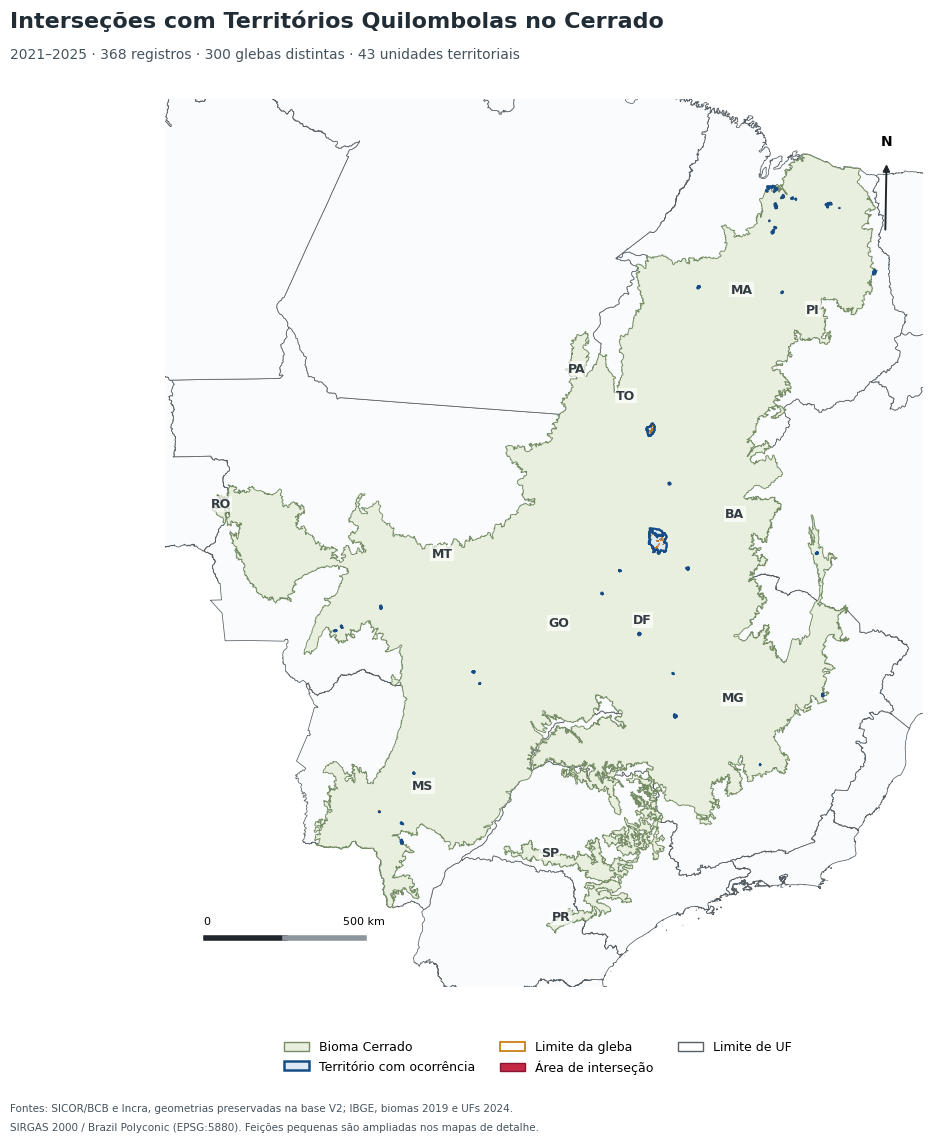

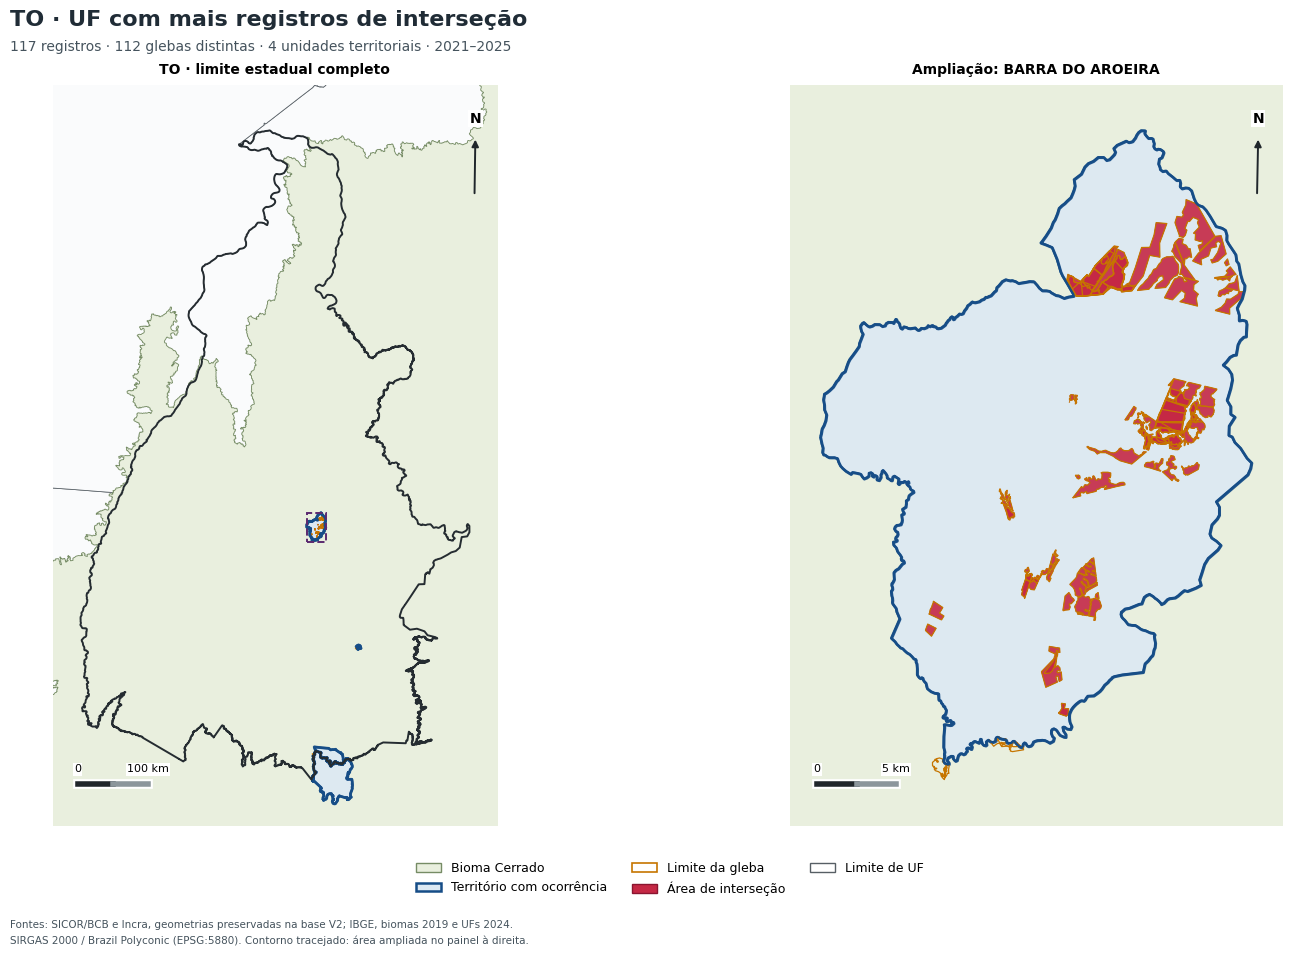

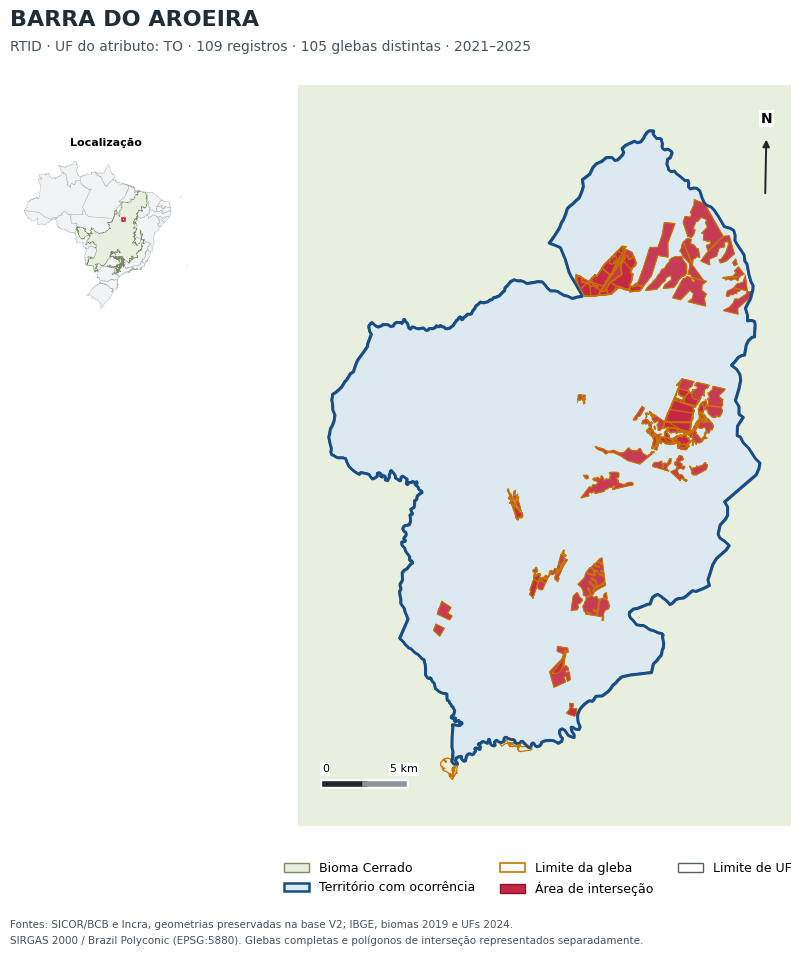

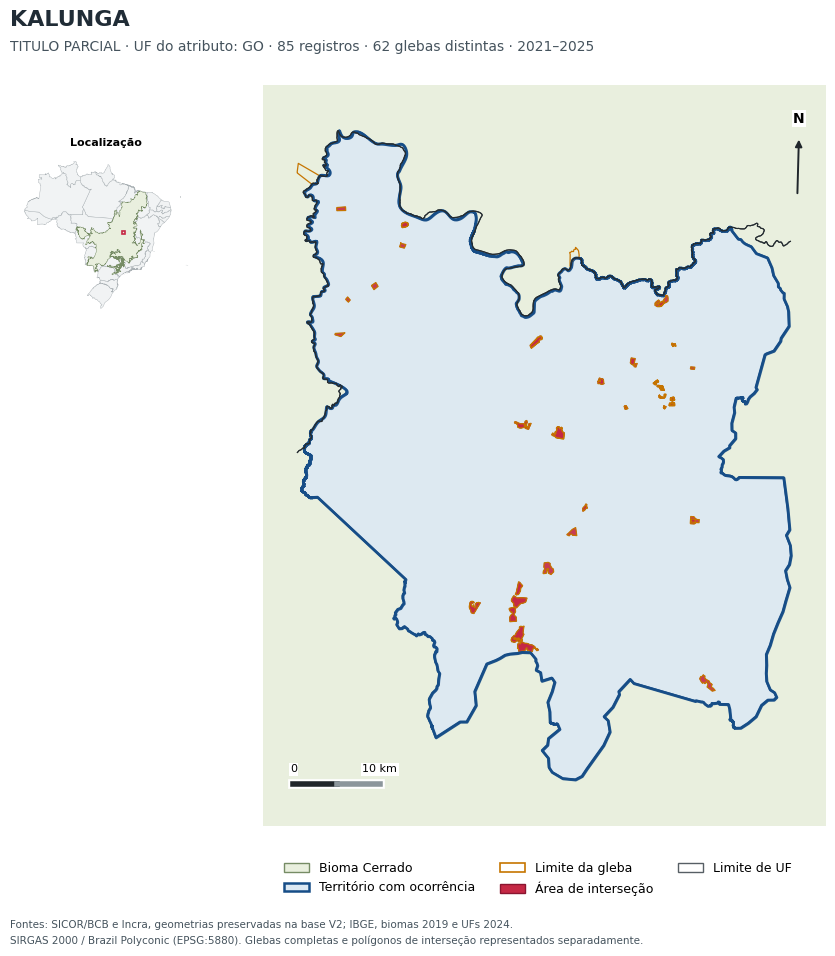

In [7]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titleweight':'bold','savefig.facecolor':'white','svg.fonttype':'none'})
COR_TQ='#164D87';COR_GLEBA='#C67500';COR_INTER='#C52845';COR_CERRADO='#E9EFDE';COR_UF='#575F65'
mapas_gerados=[]
para_ll=Transformer.from_crs(CRS_ANALISE,4674,always_xy=True)
para_xy=Transformer.from_crs(4674,CRS_ANALISE,always_xy=True)
geod=Geod(ellps='GRS80')

def serie(geom):return gpd.GeoSeries([geom],crs=CRS_ANALISE)
def enquadrar(ax,bounds,margem=0.07):
    a,b,c,d=map(float,bounds);w=max(c-a,1000);h=max(d-b,1000)
    ax.set_xlim(a-margem*w,c+margem*w);ax.set_ylim(b-margem*h,d+margem*h)
    ax.set_aspect('equal');ax.set_axis_off()

def perto(z,bounds):
    ids=z.sindex.query(box(*bounds),predicate='intersects')
    return z.iloc[ids]

def adornos(ax):
    a,c=ax.get_xlim();b,d=ax.get_ylim();w=c-a;h=d-b
    # Barra horizontal com comprimento calibrado geodesicamente no local.
    x0=a+0.055*w;y0=b+0.055*h
    lo,la=para_ll.transform(x0,y0);lo2,la2=para_ll.transform(x0+0.23*w,y0)
    _,_,dist=geod.inv(lo,la,lo2,la2)
    exp=10**math.floor(math.log10(max(dist,1)))
    length=max(v for v in [1*exp,2*exp,5*exp,10*exp,0.5*exp] if v<=dist)
    dx=0.23*w*length/dist
    ax.plot([x0,x0+dx],[y0,y0],color='white',lw=7,zorder=30)
    ax.plot([x0,x0+dx/2],[y0,y0],color='#20262B',lw=4,zorder=31)
    ax.plot([x0+dx/2,x0+dx],[y0,y0],color='#8C969C',lw=4,zorder=31)
    txt=f'{length/1000:g} km' if length>=1000 else f'{length:g} m'
    ax.text(x0,y0+0.016*h,'0',fontsize=8,zorder=32,ha='center',bbox=dict(fc='white',ec='none',pad=1))
    ax.text(x0+dx,y0+0.016*h,txt,fontsize=8,zorder=32,ha='center',bbox=dict(fc='white',ec='none',pad=1))
    # Norte verdadeiro no ponto de implantação da seta.
    nx=a+0.95*w;ny=b+0.85*h;lon,lat=para_ll.transform(nx,ny)
    xx,yy=para_xy.transform(lon,lat+0.1);vx=xx-nx;vy=yy-ny;norm=math.hypot(vx,vy)
    ex=nx+vx/norm*h*0.08;ey=ny+vy/norm*h*0.08
    ax.annotate('',xy=(ex,ey),xytext=(nx,ny),arrowprops=dict(arrowstyle='-|>',color='#20262B',lw=1.4),zorder=35)
    ax.text(ex,ey+0.015*h,'N',ha='center',va='bottom',weight='bold',fontsize=10,zorder=35,bbox=dict(fc='white',ec='none',pad=1))

def desenhar(ax,territorio_ids,gleba_ids,ocorrencias,bounds,escala='geral',estado=None):
    a,b,c,d=bounds;w=max(c-a,1000);h=max(d-b,1000)
    janela=box(a-.10*w,b-.10*h,c+.10*w,d+.10*h)
    bg=perto(ufs,janela.bounds).copy()
    bg.geometry=bg.geometry.intersection(janela)
    bg.plot(ax=ax,facecolor='#FAFBFC',edgecolor=COR_UF,linewidth=0.55,zorder=0)
    contexto=cerrado.intersection(janela)
    if not contexto.is_empty:serie(contexto).plot(ax=ax,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=0.65,zorder=1)
    ts=territorios.loc[territorios.unidade.isin(territorio_ids)];gs=glebas.loc[glebas.gleba.isin(gleba_ids)]
    if not ts.empty:ts.plot(ax=ax,facecolor='#DDE9F3',edgecolor=COR_TQ,linewidth=1.5 if escala=='geral' else 2.0,alpha=0.95,zorder=3)
    if not ocorrencias.empty:ocorrencias.plot(ax=ax,facecolor=COR_INTER,edgecolor='#8A1530',linewidth=0.35,alpha=0.90,zorder=5)
    if not gs.empty:gs.boundary.plot(ax=ax,color=COR_GLEBA,linewidth=0.65 if escala=='geral' else 0.9,zorder=6)
    # Redesenha o contorno do território sobre as interseções.
    if not ts.empty:ts.boundary.plot(ax=ax,color=COR_TQ,linewidth=1.2 if escala=='geral' else 1.65,zorder=7)
    if estado is not None:serie(estado).boundary.plot(ax=ax,color='#252C31',linewidth=1.4,zorder=7)
    enquadrar(ax,bounds);adornos(ax)

handles=[Patch(facecolor=COR_CERRADO,edgecolor='#768C65',label='Bioma Cerrado'),
         Patch(facecolor='#DDE9F3',edgecolor=COR_TQ,linewidth=1.8,label='Território com ocorrência'),
         Patch(facecolor='none',edgecolor=COR_GLEBA,linewidth=1.2,label='Limite da gleba'),
         Patch(facecolor=COR_INTER,edgecolor='#8A1530',label='Área de interseção'),
         Patch(facecolor='none',edgecolor=COR_UF,linewidth=1,label='Limite de UF')]

def finalizar(fig,nome,titulo,subtitulo,nota=''):
    fig.suptitle(titulo,x=0.06,y=0.965,ha='left',fontsize=16,weight='bold',color='#202C36')
    fig.text(0.06,0.924,subtitulo,ha='left',fontsize=10,color='#45535D')
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(0.5,0.068),ncol=3,frameon=False,fontsize=9)
    fonte='Fontes: SICOR/BCB e Incra, geometrias preservadas na base V2; IBGE, biomas 2019 e UFs 2024.'
    if ARQUIVO_UFS or ARQUIVO_BIOMAS:fonte='Fontes: SICOR/BCB e Incra (base V2); '+FONTE_BIOMAS+'; '+FONTE_UFS+'.'
    fig.text(0.06,0.047,fonte,fontsize=7.5,color='#45535D')
    fig.text(0.06,0.031,'SIRGAS 2000 / Brazil Polyconic (EPSG:5880). '+nota,fontsize=7.5,color='#45535D')
    fig.subplots_adjust(left=0.04,right=0.97,bottom=0.15,top=0.89)
    for ext in FORMATOS:fig.savefig(SAIDA/'mapas'/f'{nome}.{ext}',dpi=DPI)
    mapas_gerados.append({'arquivo':nome,'titulo':titulo,'subtitulo':subtitulo,'nota':nota})
    if MOSTRAR_FIGURAS:plt.show()
    plt.close(fig)

fig,ax=plt.subplots(figsize=(12,12))
desenhar(ax,territorios.unidade,glebas.gleba,x,cerrado.bounds)
for _,u in ufs.loc[ufs.intersects(cerrado)].iterrows():
    pt=u.geometry.intersection(cerrado).representative_point()
    ax.text(pt.x,pt.y,u.UF,fontsize=9,weight='bold',color='#323B41',ha='center',zorder=20,
            bbox=dict(fc='white',ec='none',alpha=0.65,pad=1))
finalizar(fig,'01_cerrado_territorios_contornos_reforcados','Interseções com Territórios Quilombolas no Cerrado',
          f"2021–2025 · {len(x):,} registros · {len(glebas):,} glebas distintas · {len(territorios)} unidades territoriais".replace(',','.'),
          'Feições pequenas são ampliadas nos mapas de detalhe.')

# Estado completo à esquerda e ampliação do território com mais registros nesse estado à direita.
z=xuf.loc[xuf.UF.eq(UF_TOP)].copy();estado=ufs.loc[ufs.UF.eq(UF_TOP)].geometry.iloc[0]
rank_local=z.groupby('unidade').linha.nunique().rename('n').reset_index().merge(territorios[['unidade','nome']],on='unidade')
top_local=rank_local.sort_values(['n','nome','unidade'],ascending=[False,True,True]).iloc[0].unidade
zl=z.loc[z.unidade.eq(top_local)];territorio_local=territorios.loc[territorios.unidade.eq(top_local)].iloc[0]
gl_local=glebas.loc[glebas.gleba.isin(zl.gleba)]
bdet=serie(shapely.union_all([territorio_local.geometry,*gl_local.geometry])).total_bounds
fig,axs=plt.subplots(1,2,figsize=(15,10),gridspec_kw={'width_ratios':[1,1.15]})
desenhar(axs[0],z.unidade.unique(),z.gleba.unique(),z,estado.bounds,'estado',estado)
desenhar(axs[1],[top_local],zl.gleba.unique(),zl,bdet,'detalhe',estado)
axs[0].set_title(f'{UF_TOP} · limite estadual completo',fontsize=10,pad=8)
axs[1].set_title('Ampliação: '+territorio_local['nome'],fontsize=10,pad=8)
a,b,c,e=bdet;axs[0].add_patch(Rectangle((a,b),c-a,e-b,fill=False,edgecolor='#5B296F',linewidth=1.4,linestyle='--',zorder=25))
finalizar(fig,'02_uf_mais_casos_com_ampliacao',f'{UF_TOP} · UF com mais registros de interseção',
          f'{z.linha.nunique()} registros · {z.gleba.nunique()} glebas distintas · {z.unidade.nunique()} unidades territoriais · 2021–2025',
          'Contorno tracejado: área ampliada no painel à direita.')

for pos,ident in enumerate(TOP_TERRITORIOS,1):
    t=territorios.loc[territorios.unidade.eq(ident)].iloc[0];zi=x.loc[x.unidade.eq(ident)]
    gi=glebas.loc[glebas.gleba.isin(zi.gleba)]
    limites=serie(shapely.union_all([t.geometry,*gi.geometry])).total_bounds
    fig,ax=plt.subplots(figsize=(12,10))
    desenhar(ax,[ident],gi.gleba,zi,limites,'detalhe')
    # Limites estaduais, quando presentes no enquadramento, sempre visíveis.
    limites_uf=perto(ufs,limites).boundary.intersection(box(*limites))
    limites_uf=limites_uf.loc[~limites_uf.is_empty]
    if not limites_uf.empty:limites_uf.plot(ax=ax,color='#252C31',linewidth=0.8,zorder=7)
    # Miniatura em espaço próprio, fora do mapa principal e da seta norte.
    # Simplificação exclusiva da miniatura; cálculos e mapas principais usam as geometrias integrais.
    en=fig.add_axes([0.065,0.64,0.15,0.20])
    ufs.geometry.simplify(1500,preserve_topology=True).plot(ax=en,facecolor='#F1F3F4',edgecolor='#AAB1B5',linewidth=0.3)
    serie(cerrado.simplify(1500,preserve_topology=True)).plot(ax=en,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=0.3)
    # Retângulo de localização no Brasil; não representa a área da gleba.
    a,b,c,e=limites;en.add_patch(Rectangle((a,b),max(c-a,80000),max(e-b,80000),fill=False,edgecolor=COR_INTER,linewidth=1.2))
    en.set_axis_off();en.set_title('Localização',fontsize=8)
    m=por_territorio.loc[por_territorio.unidade.eq(ident)].iloc[0]
    titulo='\n'.join(textwrap.wrap(t['nome'],width=65))
    finalizar(fig,f'{pos+2:02d}_territorio_{ident}_detalhe',titulo,
       f"{t.fase} · UF do atributo: {t.uf_territorio} · {m.registros} registros · {m.glebas} glebas distintas · 2021–2025",
       'Glebas completas e polígonos de interseção representados separadamente.')


## 8. Tabelas para o Word e observações para revisar o texto
A tabela completa reúne todos os territórios, com o nome recuperado de `QUIL_NM_COMUNID`. O total geral é recalculado, sem somar glebas ou áreas de união entre grupos.

A auditoria permite corrigir o rótulo “sem nome” do código 17. **Novo Acordo aparece no relatório de municípios**; sua área municipal não deve ser apresentada como resultado de outro território. A numeração das tabelas e figuras deve seguir a sequência da dissertação, após a inclusão dos resultados de 5.5.1.


In [8]:
def br(v,casas=0):
    if pd.isna(v):return 'Não informado'
    return f'{float(v):,.{casas}f}'.replace(',','X').replace('.',',').replace('X','.')
cols=['unidade','nome','fase','uf_territorio','registros','glebas','refs','area_acumulada_ha','area_uniao_ha']
tab=por_territorio[cols].copy()
# Totais distintos recalculados; a união geral não é a soma das uniões por território.
tot={'unidade':'TOTAL','nome':'Conjunto completo','fase':'—','uf_territorio':'—',**geral}
tab=pd.concat([tab,pd.DataFrame([{k:tot[k] for k in cols}])],ignore_index=True)
for c in ['registros','glebas','refs']:tab[c]=tab[c].map(br)
for c in ['area_acumulada_ha','area_uniao_ha']:tab[c]=tab[c].map(lambda v:br(v,4))
tab.columns=['ID interno','Território Quilombola','Etapa','UF informada','Registros','Glebas distintas','REF_BACEN distintos','Área acumulada (ha)','Área da união (ha)']
nota=('Fonte: elaborado pelo autor com base nas interseções SICOR × Incra, versão 2, e auditoria desta execução. '
      'Registros correspondem às linhas originais. Glebas e referências podem ocorrer em várias unidades. '
      'IDs internos distintos são preservados, inclusive para nomes iguais e fases diferentes. '
      'A união global e as contagens distintas são recalculadas, não somadas entre unidades. Áreas em EPSG:5880.')
html=('<!doctype html><html lang="pt-BR"><meta charset="utf-8"><style>body{font:12px Arial;margin:24px}table{border-collapse:collapse;width:100%}th,td{padding:7px;border:1px solid #bbb}th{background:#e4edf4}p{line-height:1.5}</style>'
      '<h2>Interseções por Território Quilombola — Cerrado, 2021–2025</h2>'+tab.to_html(index=False,escape=True,border=0)+'<p>'+nota+'</p></html>')
(SAIDA/'tabelas'/'tabela_completa_para_word.html').write_text(html,encoding='utf-8')
with pd.ExcelWriter(SAIDA/'tabelas'/'Totais_Territorios_Quilombolas_5_5_2.xlsx',engine='openpyxl') as writer:
    for name,z in [('Por território',por_territorio),('Total geral',pd.DataFrame([geral])),('Ranking UFs',por_uf),('Por etapa',por_etapa),('Identificacao',auditoria_nomes),('Auditoria UF',auditoria_uf),('Conferencia areas UF',conferencia_uf),('Conferencia V2',conferencia)]:
        z.to_excel(writer,sheet_name=name,index=False)
        ws=writer.sheets[name];ws.freeze_panes='A2';ws.auto_filter.ref=ws.dimensions
        from openpyxl.styles import Font,PatternFill,Alignment
        for cell in ws[1]:cell.font=Font(bold=True,color='FFFFFF');cell.fill=PatternFill('solid',fgColor='164D87')
        for column in ws.columns:
            letter=column[0].column_letter;ws.column_dimensions[letter].width=min(42,max(14,max(len(str(c.value or '')) for c in column)+2))
    pd.DataFrame({'Notas':[nota,'Soma_valores_linhas: soma dos valores de todas as linhas; não é montante exclusivo contratado, desembolsado ou irregular.','Ranking UF: área positiva da interseção em cada UF; cada registro conta uma vez por UF.','Casos e seleção de territórios: quantidade de registros, não área nem número de produtores.']}).to_excel(writer,sheet_name='Leia-me',index=False)

selecionadas=por_territorio.head(NUMERO_TERRITORIOS_DETALHE)
texto=(f"Foram examinados {br(geral['registros'])} registros, associados a {br(geral['glebas'])} glebas distintas, "
       f"{br(geral['territorios'])} unidades territoriais e {br(geral['refs'])} referências BACEN distintas. "
       f"A área acumulada foi de {br(geral['area_acumulada_ha'],2)} ha e a união geométrica de {br(geral['area_uniao_ha'],2)} ha.\n\n"
       f"A UF com mais registros foi {UF_TOP}, com {br(por_uf.iloc[0].registros)} ocorrências. "
       "A seleção estadual contou cada linha original uma vez por UF com área positiva de interseção, sem multiplicar partes municipais.\n\n"
       "As unidades selecionadas para os mapas individuais, ordenadas pelo número de registros, foram:\n")
for _,r in selecionadas.iterrows():
    texto+=f"- {r['nome']} (ID {r.unidade}; {r.fase}; {r.uf_territorio}): {br(r.registros)} registros, {br(r.glebas)} glebas, {br(r.refs)} REF_BACEN distintos e {br(r.area_uniao_ha,2)} ha de união.\n"
texto+=('\nA tabela completa está em CSV, Excel e HTML. O mapa geral reforça os contornos dos territórios; '
        'o mapa da UF inclui ampliação, e os mapas individuais distinguem território, gleba completa e área intersectada. '
        'Os limites de território são os preservados na base V2. Somente unidades com ocorrência na amostra são representadas. '
        'Os resultados são ocorrências de triagem espacial e não comprovação automática de concessões irregulares.\n\n'
        'A soma financeira é a soma dos valores presentes nas linhas, sujeita a repetições administrativas; não equivale a crédito exclusivo da área de interseção. '
        'O período refere-se ao ANO_OPERACAO dos registros. Os atributos de fase são os da base territorial utilizada; não reconstituem automaticamente a fase na contratação.\n')
(SAIDA/'resultados_para_resposta_ao_orientador.txt').write_text(texto,encoding='utf-8')
legendas=[]
for m in mapas_gerados:
    legendas.append(m['arquivo']+'\n'+m['titulo'].replace('\n',' ')+' — '+m['subtitulo']+'.\n'+m['nota']+'\n'+nota+'\n')
(SAIDA/'legendas_das_figuras.txt').write_text('\n'.join(legendas),encoding='utf-8')
print(texto)

observacoes=[
 'Os nomes foram extraídos de QUIL_NM_COMUNID; o resumo anterior não identificava esse campo.',
 'Novo Acordo é município no arquivo 09_resumo_por_municipio.csv. Não é uma unidade quilombola adicional na tabela por território.',
 'A UF informada em QUIL_CD_UF é mantida nas tabelas de atributos. O ranking de UFs usa o recorte das interseções pelos estados.',
 'Diferenças entre atributos e geometria estão em auditoria_uf_atributo_versus_espacial.csv; não houve alteração silenciosa da base.',
 'A classificação INCRA é preservada como atributo literal; não é reinterpretada como etapa jurídica de regularização.',
 'A contagem preserva todas as linhas da versão 2; os mapas de contexto representam apenas territórios com ocorrência.'
]
ident17=por_territorio.loc[por_territorio.unidade.eq('17')]
if not ident17.empty:
    r=ident17.iloc[0]
    observacoes.insert(1,f"Código 17: {r['nome']}; {r.registros} registros; {br(r.area_uniao_ha,2)} ha de união geométrica.")
(SAIDA/'observacoes_para_revisao_do_subcapitulo.txt').write_text('\n'.join(observacoes),encoding='utf-8')
print('\n'.join(observacoes))

complemento=(f"\nA soma das contagens por UF é {int(por_uf.registros.sum())}; há {len(linhas_multiuf)} registro(s) presente(s) em mais de uma UF. "
             "O total global continua sendo o número de linhas originais.\n"
             "As áreas estaduais foram recalculadas diretamente com a malha IBGE 2024. A conferência com as áreas citadas no texto anterior está na planilha e no CSV específico; esses valores podem diferir dos obtidos por partes municipais.\n")
with (SAIDA/'resultados_para_resposta_ao_orientador.txt').open('a',encoding='utf-8') as f:f.write(complemento)


Foram examinados 368 registros, associados a 300 glebas distintas, 43 unidades territoriais e 234 referências BACEN distintas. A área acumulada foi de 15.016,01 ha e a união geométrica de 9.367,44 ha.

A UF com mais registros foi TO, com 117 ocorrências. A seleção estadual contou cada linha original uma vez por UF com área positiva de interseção, sem multiplicar partes municipais.

As unidades selecionadas para os mapas individuais, ordenadas pelo número de registros, foram:
- BARRA DO AROEIRA (ID 17; RTID; TO): 109 registros, 105 glebas, 31 REF_BACEN distintos e 4.597,77 ha de união.
- KALUNGA (ID 136; TITULO PARCIAL; GO): 85 registros, 62 glebas, 81 REF_BACEN distintos e 1.742,54 ha de união.

A tabela completa está em CSV, Excel e HTML. O mapa geral reforça os contornos dos territórios; o mapa da UF inclui ampliação, e os mapas individuais distinguem território, gleba completa e área intersectada. Os limites de território são os preservados na base V2. Somente unidades com ocorrênci

## 9. Registrar a execução e baixar os resultados

In [9]:
metadados={'execucao_utc':datetime.now(timezone.utc).isoformat(),'origens':ORIGENS,'crs_wkt':CRS_WKT,'crs_calculo':CRS_ANALISE,
 'fontes_contexto':{'ufs':FONTE_UFS,'biomas':FONTE_BIOMAS},'colunas':C,'anos':ANOS,'deduplicacao_analitica':False,
 'unidade_caso':'Linha original da base espacial V2','criterio_selecao':'Quantidade de registros decrescente; desempate por nome/ID ou sigla UF',
 'uf_selecionada':UF_TOP,'territorios_selecionados':TOP_TERRITORIOS,'totais':{k:float(v) if isinstance(v,(np.floating,np.integer)) else v for k,v in geral.items()},
 'contexto_territorios':'Somente territórios com ocorrência, limites integrais extraídos da base V2','mapas':mapas_gerados,'coluna_nome':'QUIL_NM_COMUNID','divergencias_uf_atributo':int((~auditoria_uf.uf_informada_inclui_uf_espacial).sum()),
 'diferenca_corte_estadual_ha':residuo,'confere_totais_referencia':bool(conferencia.confere.all()),
 'versoes':{'python':platform.python_version(),'pandas':pd.__version__,'geopandas':gpd.__version__,'shapely':shapely.__version__}}
(SAIDA/'metadados.json').write_text(json.dumps(metadados,ensure_ascii=False,indent=2),encoding='utf-8')
zip_final=SAIDA/'Resultados_Territorios_Quilombolas_5_5_2.zip'
with zipfile.ZipFile(zip_final,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SAIDA.rglob('*')):
        if p.is_file() and p!=zip_final:z.write(p,arcname=str(p.relative_to(SAIDA)))
print('Resultados salvos em:',SAIDA)
print('ZIP:',zip_final)
if BAIXAR_ZIP:
    from google.colab import files
    files.download(str(zip_final))


Resultados salvos em: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_quilombolas_5_5_2/20260918_003856_312065
ZIP: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_quilombolas_5_5_2/20260918_003856_312065/Resultados_Territorios_Quilombolas_5_5_2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>